# AIMLZC416 — Mathematical Foundations for Machine Learning
## Assignment 2: Optimization Using Python
**M.Tech in AI & ML, WILP, BITS Pilani**

---
* **Name:** `Prahlad Vinayak Avadhani`
* **BITS ID:** `2026AJ05253`
* **Course:** `AIMLZC416 — Mathematical Foundations for Machine Learning`
* **Assignment:** `Assignment 2`
---

### Assignment Notes:
- All optimizers are written from scratch using NumPy without using optimization libraries like `scipy.optimize`.
- Plots are created using Matplotlib with appropriate labels, legends, and titles.


## Question 1. Exact Line Search for a Quadratic Objective

Objective function:
$$J(w) = \frac{1}{2} w^T A w + b^T w$$

### 1(a) Implementation Details
- **Gradient:** $\nabla J(w) = Aw + b$
- **Search direction (negative gradient):** $g_t = -(Aw_t + b)$
- **Exact step size:** We choose $\alpha_t$ to minimize $J(w_t + \alpha g_t)$. Setting the derivative to 0 gives:
  $$\alpha_t = \frac{g_t^T g_t}{g_t^T A g_t}$$
- **Update rule:** $w_{t+1} = w_t + \alpha_t g_t$
- **Stopping condition:** Stop when $\|Aw_t + b\|_2 < 10^{-10}$ or after `num_steps` iterations.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

def exact_line_search_quadratic(A, b, w0, num_steps):
    """
    Performs exact line search for the quadratic objective J(w) = 0.5 * w^T A w + b^T w.

    Parameters:
    -----------
    A : numpy.ndarray of shape (n, n)
        Symmetric positive-definite matrix.
    b : numpy.ndarray of shape (n,)
        Linear term vector.
    w0 : numpy.ndarray of shape (n,)
        Initial starting point vector.
    num_steps : int
        Maximum number of iterations to perform.

    Returns:
    --------
    iterates : list of numpy.ndarray
        List containing copies of the initial point and every point generated.
        iterates[0] is w0, iterates[t] is w_t, and the list has at most num_steps + 1 entries.
    """
    A = np.asarray(A, dtype=np.float64)
    b = np.asarray(b, dtype=np.float64)
    w = np.asarray(w0, dtype=np.float64).copy()

    # Store initial point as an independent copy
    iterates = [w.copy()]

    for _ in range(num_steps):
        grad = A @ w + b
        
        # Stop if ||Aw_t + b||_2 < 10^-10
        if np.linalg.norm(grad, ord=2) < 1e-10:
            break

        g = -grad
        gt_g = float(g.T @ g)
        gt_A_g = float(g.T @ (A @ g))

        # Safely guard against division by zero if gradient is numerically zero or denominator degenerate
        if gt_A_g <= 0.0:
            break

        alpha = gt_g / gt_A_g
        w = w + alpha * g
        iterates.append(w.copy())

    return iterates

def quadratic_objective(A, b, w):
    """Evaluates J(w) = 0.5 * w^T A w + b^T w."""
    w = np.asarray(w, dtype=np.float64)
    return float(0.5 * w.T @ (A @ w) + b.T @ w)


### 1(b) Running the Function and Checking Orthogonality

Given parameters:
$$A = \begin{bmatrix} 2 & 0 \\ 0 & 8 \end{bmatrix}, \quad b = \begin{bmatrix} 0 \\ 0 \end{bmatrix}, \quad w_0 = \begin{bmatrix} 2.0 \\ 1.0 \end{bmatrix}$$

This gives the objective:
$$J(w_1, w_2) = w_1^2 + 4w_2^2$$

We run the function with `num_steps = 10`, print each iterate and its objective value, and check the dot products $g_t^T g_{t+1}$ for $t = 0, 1, 2, 3, 4$.


In [2]:
# Define system parameters
A = np.array([[2.0, 0.0],
              [0.0, 8.0]], dtype=np.float64)
b = np.array([0.0, 0.0], dtype=np.float64)
w0 = np.array([2.0, 1.0], dtype=np.float64)
num_steps = 10

# Execute exact line search
iterates = exact_line_search_quadratic(A, b, w0, num_steps)

# 1 & 2. Print w0, every iterate, and J(w_t)
print("1 & 2. Iterates and Objective Values J(w_t):")
print(f"{'t':<4} | {'w_t':<32} | {'J(w_t) = w1^2 + 4*w2^2':<24} | {'||grad||_2':<12}")
print("-" * 78)
for t, w in enumerate(iterates):
    loss = quadratic_objective(A, b, w)
    grad_norm = np.linalg.norm(A @ w + b)
    print(f"{t:<4} | [{w[0]:14.8f}, {w[1]:14.8f}] | {loss:24.10f} | {grad_norm:12.6e}")

print(f"\nTotal returned points: {len(iterates)} (initial point w0 + {len(iterates)-1} updates)\n")

# 3. For t = 0, 1, 2, 3, 4, calculate and print g_t^T g_{t+1}
print("3. Successive Gradient Dot Products: g_t^T g_{t+1} for t = 0, 1, 2, 3, 4")
print(f"{'t':<4} | {'g_t^T g_{t+1}':<24} | {'Approximately zero (< 1e-10)?'}")
print("-" * 62)
for t in range(5):
    wt = iterates[t]
    wt_next = iterates[t + 1]
    gt = -(A @ wt + b)
    gt_next = -(A @ wt_next + b)
    dot_prod = float(np.dot(gt, gt_next))
    is_approx_zero = abs(dot_prod) < 1e-10
    print(f"{t:<4} | {dot_prod:24.15e} | {is_approx_zero}")

print("\nAre the dot products approximately zero within floating-point precision?")
print("Yes. The dot products are extremely small, between 10^-15 and 10^-17.")
print("In standard Python (double precision floats), numbers this small are zero within numerical precision.")


1 & 2. Iterates and Objective Values J(w_t):
t    | w_t                              | J(w_t) = w1^2 + 4*w2^2   | ||grad||_2  
------------------------------------------------------------------------------
0    | [    2.00000000,     1.00000000] |             8.0000000000 | 8.944272e+00
1    | [    1.41176471,    -0.17647059] |             2.1176470588 | 3.156802e+00
2    | [    0.52941176,     0.26470588] |             0.5605536332 | 2.367601e+00
3    | [    0.37370242,    -0.04671280] |             0.1483818441 | 8.356240e-01
4    | [    0.14013841,     0.07006920] |             0.0392775470 | 6.267180e-01
5    | [    0.09892123,    -0.01236515] |             0.0103969977 | 2.211946e-01
6    | [    0.03709546,     0.01854773] |             0.0027521465 | 1.658959e-01
7    | [    0.02618503,    -0.00327313] |             0.0007285094 | 5.855151e-02
8    | [    0.00981939,     0.00490969] |             0.0001928407 | 4.391363e-02
9    | [    0.00693133,    -0.00086642] |             0.

### Why Consecutive Directions are Orthogonal ($90^\circ$ Turns)

In exact line search, $\alpha_t$ is chosen so that $J(w_t + \alpha g_t)$ is at its minimum along the line.

At the minimum, the derivative along the search direction must be zero:
$$\nabla J(w_{t+1})^T g_t = 0$$

Since $g_{t+1} = -\nabla J(w_{t+1})$, this gives:
$$g_t^T g_{t+1} = 0$$

Because consecutive directions are perpendicular ($90^\circ$), the path turns by about $90^\circ$ at each intermediate point.
*(Note: Per assignment instructions, this is an orthogonal turn between consecutive path segments, not a point of tangency to the contour line).*


### 1(c) Plotting the Optimization Path

We plot the contour lines of $J(w_1, w_2) = w_1^2 + 4w_2^2$ and overlay the path $w_0 \to \dots \to w_{10}$.
- Marks the start point $w_0$, the iterates, and the minimizer $(0, 0)$.
- Connects consecutive iterates with lines.
- Marks the angle at each step to show the roughly $90^\circ$ turn.
- Uses equal axis scaling so the right angles look square.


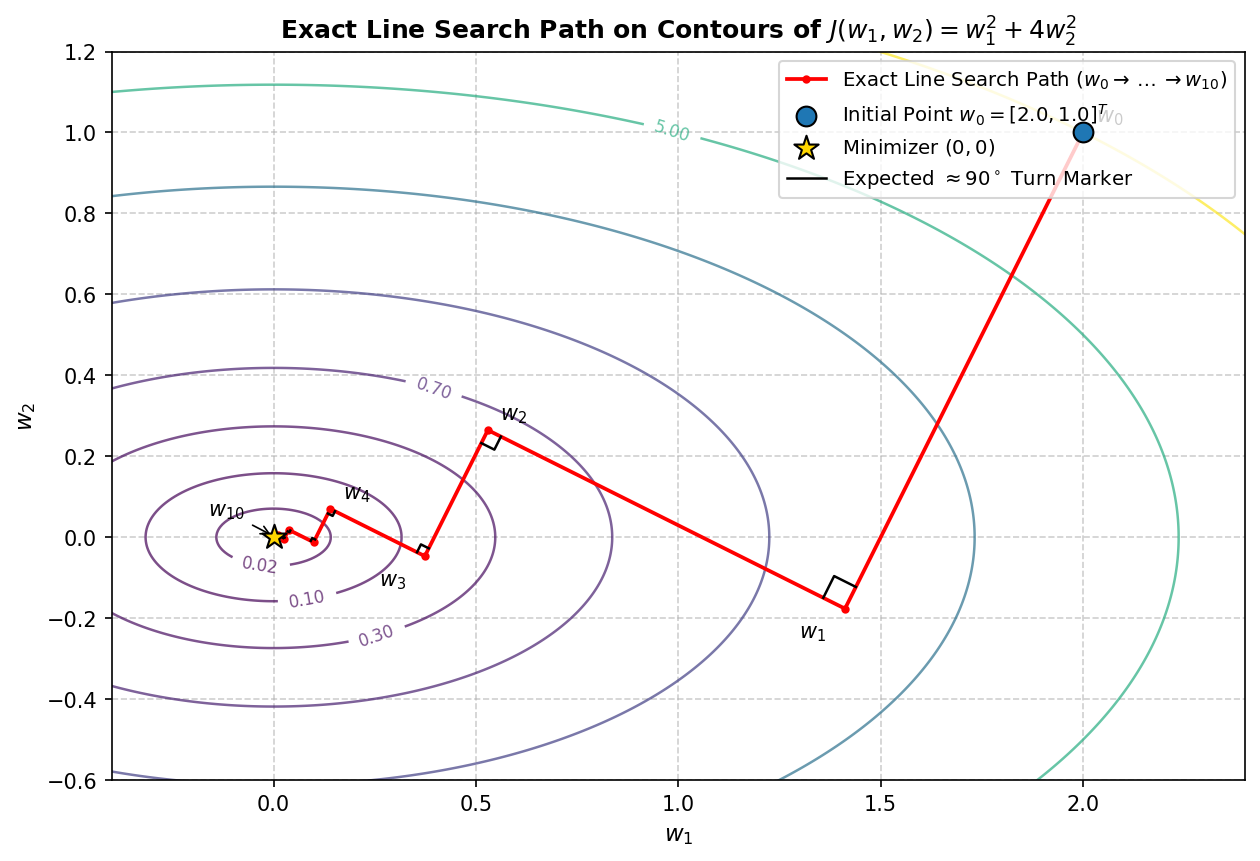

In [3]:
iter_arr = np.array(iterates)

fig, ax = plt.subplots(figsize=(8.5, 7.5), dpi=150)

# Coordinate grid for contours
w1_vals = np.linspace(-0.6, 2.5, 400)
w2_vals = np.linspace(-0.8, 1.3, 400)
W1, W2 = np.meshgrid(w1_vals, w2_vals)
J_grid = W1**2 + 4.0 * W2**2

contour_levels = [0.02, 0.1, 0.3, 0.7, 1.5, 3.0, 5.0, 8.0]
cs = ax.contour(W1, W2, J_grid, levels=contour_levels, cmap='viridis', alpha=0.7, linewidths=1.2)
ax.clabel(cs, inline=True, fontsize=8, fmt='%.2f')

# Overlay path
ax.plot(iter_arr[:, 0], iter_arr[:, 1], 'r.-', linewidth=1.8, markersize=6,
        label=r'Exact Line Search Path ($w_0 \to \dots \to w_{10}$)', zorder=4)

# Initial point and minimizer
ax.scatter(iter_arr[0, 0], iter_arr[0, 1], color='#1f77b4', s=90, zorder=6,
           label=r'Initial Point $w_0 = [2.0, 1.0]^T$', edgecolor='black')
ax.scatter(0, 0, color='gold', s=150, marker='*', zorder=6,
           label=r'Minimizer $(0, 0)$', edgecolor='black')

def draw_angle_marker(ax, pt_prev, pt_curr, pt_next, size=0.04, color='black', lw=1.2):
    """Visually marks the angle between incoming and outgoing path segments."""
    u = pt_prev - pt_curr
    v = pt_next - pt_curr
    len_u = np.linalg.norm(u)
    len_v = np.linalg.norm(v)
    if len_u < 1e-5 or len_v < 1e-5:
        return
    d1 = u / len_u
    d2 = v / len_v
    s = min(len_u, len_v, size)
    p1 = pt_curr + s * d1
    p2 = pt_curr + s * d1 + s * d2
    p3 = pt_curr + s * d2
    ax.plot([p1[0], p2[0], p3[0]], [p1[1], p2[1], p3[1]], color=color, linewidth=lw, zorder=5)

# Visually mark the angle at every intermediate iterate where both adjacent segments exist
for t in range(1, len(iter_arr) - 1):
    draw_angle_marker(ax, iter_arr[t-1], iter_arr[t], iter_arr[t+1], size=0.06 * (0.6 ** (t - 1)))

# Label iterates
for t in range(min(5, len(iter_arr))):
    offset = (6, 5) if t % 2 == 0 else (-22, -14)
    ax.annotate(f'$w_{{{t}}}$', (iter_arr[t, 0], iter_arr[t, 1]),
                textcoords='offset points', xytext=offset, fontsize=10, fontweight='bold')

# Label final iterate w10 with callout arrow
ax.annotate(r'$w_{10}$', (iter_arr[10, 0], iter_arr[10, 1]),
            textcoords='offset points', xytext=(-32, 10), fontsize=10, fontweight='bold',
            arrowprops=dict(arrowstyle='->', lw=0.8, color='black'))

# Legend entry for angle marker
ax.plot([], [], 'k-', linewidth=1.2, label=r'Expected $\approx 90^\circ$ Turn Marker')

ax.set_title(r'Exact Line Search Path on Contours of $J(w_1, w_2) = w_1^2 + 4w_2^2$', fontsize=12, fontweight='bold')
ax.set_xlabel('$w_1$', fontsize=11)
ax.set_ylabel('$w_2$', fontsize=11)
ax.set_aspect('equal')
ax.set_xlim(-0.4, 2.4)
ax.set_ylim(-0.6, 1.2)
ax.grid(True, linestyle='--', alpha=0.6)
ax.legend(loc='upper right', fontsize=9.5)

plt.tight_layout()
plt.show()


## Question 2. Gradient Descent, Momentum and RMSProp

Loss function:
$$J(w_1, w_2) = w_1^2 + 10w_2^2$$

The gradient is:
$$\nabla J(w) = \begin{bmatrix} 2w_1 \\ 20w_2 \end{bmatrix}$$

Because of the factor of 10, the function is 10 times steeper along $w_2$ than along $w_1$.

### 2(a) Optimizer Update Rules

1. **Vanilla Gradient Descent:**
   $$w_{t+1} = w_t - \alpha \, \text{grad\_fn}(w_t)$$

2. **Momentum:**
   Start with $v_0 = 0$:
   $$v_{t+1} = \beta v_t + \text{grad\_fn}(w_t)$$
   $$w_{t+1} = w_t - \alpha v_{t+1}$$

3. **RMSProp:**
   Start with $s_0 = 0$:
   $$s_{t+1} = \rho s_t + (1 - \rho) (\text{grad\_fn}(w_t) \odot \text{grad\_fn}(w_t))$$
   $$w_{t+1} = w_t - \alpha \frac{\text{grad\_fn}(w_t)}{\sqrt{s_{t+1}} + \varepsilon}$$


In [4]:
def loss_fn(w):
    """Evaluates J(w1, w2) = w1^2 + 10 * w2^2."""
    w = np.asarray(w, dtype=np.float64)
    return float(w[0]**2 + 10.0 * w[1]**2)

def grad_fn(w):
    """Analytic gradient: grad_J = [2*w1, 20*w2]^T."""
    w = np.asarray(w, dtype=np.float64)
    return np.array([2.0 * w[0], 20.0 * w[1]], dtype=np.float64)

def vanilla_gd(grad_fn, w0, alpha, num_iters):
    """Vanilla Gradient Descent optimizer."""
    w = np.asarray(w0, dtype=np.float64).copy()
    iterates = [w.copy()]

    for _ in range(num_iters):
        g = grad_fn(w)
        w = w - alpha * g
        iterates.append(w.copy())

    return iterates

def momentum_gd(grad_fn, w0, alpha, beta, num_iters):
    """Momentum Gradient Descent optimizer."""
    w = np.asarray(w0, dtype=np.float64).copy()
    v = np.zeros_like(w, dtype=np.float64)
    iterates = [w.copy()]

    for _ in range(num_iters):
        g = grad_fn(w)
        v = beta * v + g
        w = w - alpha * v
        iterates.append(w.copy())

    return iterates

def rmsprop_gd(grad_fn, w0, alpha, rho, epsilon, num_iters):
    """RMSProp optimizer."""
    w = np.asarray(w0, dtype=np.float64).copy()
    s = np.zeros_like(w, dtype=np.float64)
    iterates = [w.copy()]

    for _ in range(num_iters):
        g = grad_fn(w)
        s = rho * s + (1.0 - rho) * (g * g)
        w = w - alpha * g / (np.sqrt(s) + epsilon)
        iterates.append(w.copy())

    return iterates


### 2(b.1) Parameters Setup

- Initial point: $w_0 = [3.0, 1.0]^T$
- Learning rate: $\alpha = 0.05$
- Iterations: 50 for all methods

**Chosen hyperparameters:**
- Momentum: $\beta = 0.9$ (standard momentum weight to help move along flat directions).
- RMSProp decay: $\rho = 0.9$ (moving average factor for squared gradients).
- RMSProp epsilon: $\varepsilon = 10^{-8}$ (small number to avoid division by zero).


In [5]:
# Setup
w0 = np.array([3.0, 1.0], dtype=np.float64)
alpha = 0.05
num_iters = 50

# Stated Hyperparameters
beta = 0.9
rho = 0.9
epsilon = 1e-8

print("Parameters:")
print(f"  w0 = {w0}, alpha = {alpha}, iterations = {num_iters}")
print(f"  beta = {beta}, rho = {rho}, epsilon = {epsilon:1.0e}\n")

# Run all three optimizers
vanilla_iters = vanilla_gd(grad_fn, w0, alpha, num_iters)
momentum_iters = momentum_gd(grad_fn, w0, alpha, beta, num_iters)
rmsprop_iters = rmsprop_gd(grad_fn, w0, alpha, rho, epsilon, num_iters)

v_arr = np.array(vanilla_iters)
m_arr = np.array(momentum_iters)
r_arr = np.array(rmsprop_iters)

v_losses = np.array([loss_fn(w) for w in v_arr])
m_losses = np.array([loss_fn(w) for w in m_arr])
r_losses = np.array([loss_fn(w) for w in r_arr])

# Milestone loss table
sample_steps = [0, 1, 2, 5, 10, 20, 30, 40, 50]
print(f"{'t':<4} | {'Vanilla GD J(w)':<16} | {'Momentum GD J(w)':<18} | {'RMSProp J(w)':<16}")
print("-" * 62)
for t in sample_steps:
    print(f"{t:<4} | {v_losses[t]:<16.6f} | {m_losses[t]:<18.6f} | {r_losses[t]:<16.6f}")

print("\nFinal values after 50 iterations:")
print(f"  Vanilla GD:  w_50 = [{v_arr[-1,0]:.6f}, {v_arr[-1,1]:.6f}], J(w_50) = {v_losses[-1]:.6e}")
print(f"  Momentum GD: w_50 = [{m_arr[-1,0]:.6f}, {m_arr[-1,1]:.6f}], J(w_50) = {m_losses[-1]:.6e}")
print(f"  RMSProp:     w_50 = [{r_arr[-1,0]:.6f}, {r_arr[-1,1]:.6f}], J(w_50) = {r_losses[-1]:.6e}")


Parameters:
  w0 = [3. 1.], alpha = 0.05, iterations = 50
  beta = 0.9, rho = 0.9, epsilon = 1e-08

t    | Vanilla GD J(w)  | Momentum GD J(w)   | RMSProp J(w)    
--------------------------------------------------------------
0    | 19.000000        | 19.000000          | 19.000000       
1    | 7.290000         | 7.290000           | 15.164039       
2    | 5.904900         | 12.765600          | 12.884570       
5    | 3.138106         | 6.438089           | 8.923249        
10   | 1.094190         | 3.427415           | 5.660766        
20   | 0.133028         | 2.636007           | 2.924941        
30   | 0.016173         | 0.382630           | 1.633448        
40   | 0.001966         | 0.279450           | 0.813050        
50   | 0.000239         | 0.064670           | 0.323863        

Final values after 50 iterations:
  Vanilla GD:  w_50 = [0.015461, 0.000000], J(w_50) = 2.390526e-04
  Momentum GD: w_50 = [-0.200041, -0.049652], J(w_50) = 6.466985e-02
  RMSProp:     w_50 = [0.5

### 2(b.2) Loss vs. Iteration (Log Scale)

We plot $J(w_t)$ against iteration $t$ for all three methods using a log scale on the vertical axis.

**Handling zero loss for log scale:**
If a loss value reaches zero, taking $\log(0)$ gives $-\infty$ and causes a plotting error. To avoid this, we set a small floor value for plotting:
$$J_{\text{plot}} = \max(J(w_t), 10^{-20})$$
This allows the curve to display properly without changing the actual results.


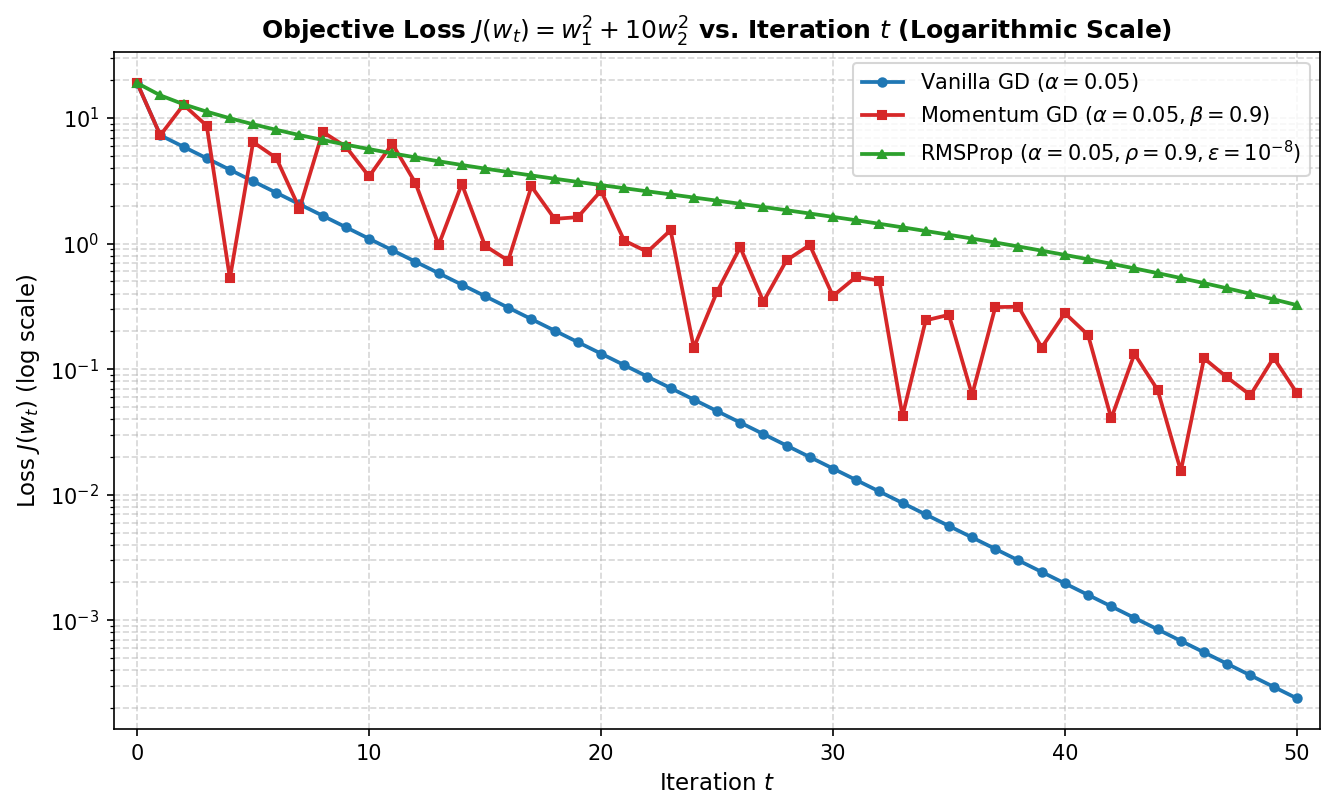

In [6]:
plt.figure(figsize=(9, 5.5), dpi=150)
iterations = np.arange(num_iters + 1)

# Safe clipping for log display without modifying original loss arrays
loss_floor = 1e-20
v_plot = np.maximum(v_losses, loss_floor)
m_plot = np.maximum(m_losses, loss_floor)
r_plot = np.maximum(r_losses, loss_floor)

plt.semilogy(iterations, v_plot, 'o-', color='#1f77b4', linewidth=1.8, markersize=4,
             label=r'Vanilla GD ($\alpha=0.05$)')
plt.semilogy(iterations, m_plot, 's-', color='#d62728', linewidth=1.8, markersize=4,
             label=r'Momentum GD ($\alpha=0.05, \beta=0.9$)')
plt.semilogy(iterations, r_plot, '^-', color='#2ca02c', linewidth=1.8, markersize=4,
             label=r'RMSProp ($\alpha=0.05, \rho=0.9, \varepsilon=10^{-8}$)')

plt.title(r'Objective Loss $J(w_t) = w_1^2 + 10w_2^2$ vs. Iteration $t$ (Logarithmic Scale)',
          fontsize=12, fontweight='bold')
plt.xlabel('Iteration $t$', fontsize=11)
plt.ylabel('Loss $J(w_t)$ (log scale)', fontsize=11)
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.legend(fontsize=10, loc='upper right')
plt.xlim(-1, 51)
plt.tight_layout()
plt.show()


### 2(b.3) Trajectory Comparison on Contour Plots

We plot the paths of all three optimizers side-by-side on the contour lines of $J(w_1, w_2) = w_1^2 + 10w_2^2$.
All three plots use the same contour levels and axis limits for a fair comparison.


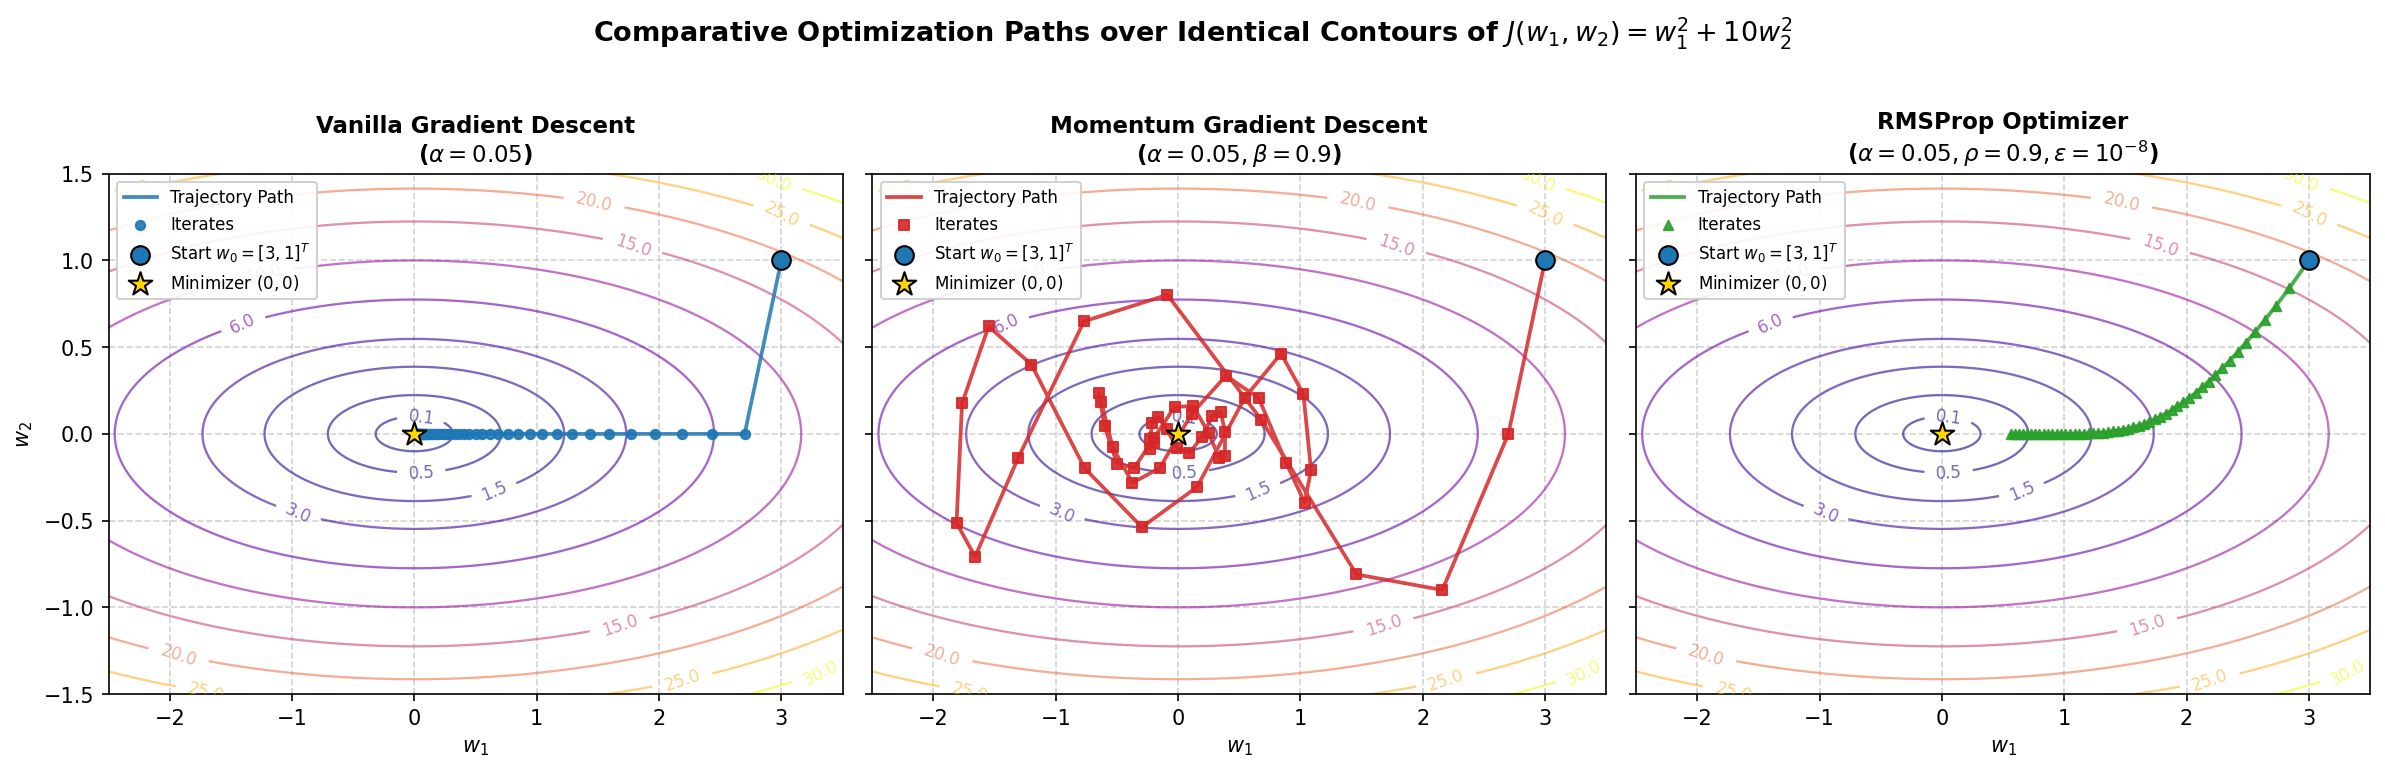

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=150, sharey=True)

# Shared grid and contour levels
w1_grid = np.linspace(-2.5, 3.5, 400)
w2_grid = np.linspace(-1.5, 1.5, 400)
W1, W2 = np.meshgrid(w1_grid, w2_grid)
J_grid = W1**2 + 10.0 * W2**2

shared_contour_levels = [0.1, 0.5, 1.5, 3.0, 6.0, 10.0, 15.0, 20.0, 25.0, 30.0]

configs = [
    (axes[0], v_arr, 'Vanilla Gradient Descent', '#1f77b4', 'o', r'$\alpha = 0.05$'),
    (axes[1], m_arr, 'Momentum Gradient Descent', '#d62728', 's', r'$\alpha = 0.05, \beta = 0.9$'),
    (axes[2], r_arr, 'RMSProp Optimizer', '#2ca02c', '^', r'$\alpha = 0.05, \rho = 0.9, \varepsilon = 10^{-8}$')
]

for ax, iters, title, color, marker, param_label in configs:
    cs = ax.contour(W1, W2, J_grid, levels=shared_contour_levels, cmap='plasma', alpha=0.6, linewidths=1.1)
    ax.clabel(cs, inline=True, fontsize=8, fmt='%.1f')

    # Path and iterates
    ax.plot(iters[:, 0], iters[:, 1], color=color, linestyle='-', linewidth=1.8, alpha=0.85, label='Trajectory Path')
    ax.scatter(iters[:, 0], iters[:, 1], color=color, s=20, marker=marker, alpha=0.9, zorder=4, label='Iterates')

    # Start point and minimizer
    ax.scatter(w0[0], w0[1], color='#1f77b4', s=80, marker='o', edgecolor='black', zorder=5, label=r'Start $w_0=[3, 1]^T$')
    ax.scatter(0, 0, color='gold', s=140, marker='*', edgecolor='black', zorder=5, label=r'Minimizer $(0, 0)$')

    ax.set_title(f'{title}\n({param_label})', fontsize=11, fontweight='bold')
    ax.set_xlabel('$w_1$', fontsize=10)
    ax.set_xlim(-2.5, 3.5)
    ax.set_ylim(-1.5, 1.5)
    ax.grid(True, linestyle='--', alpha=0.55)
    ax.legend(fontsize=8, loc='upper left', framealpha=0.9)

axes[0].set_ylabel('$w_2$', fontsize=10)

plt.suptitle(r'Comparative Optimization Paths over Identical Contours of $J(w_1, w_2) = w_1^2 + 10w_2^2$',
             fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


### 2.5 Observations and Comparison

1. **Vanilla Gradient Descent:**
   - Along $w_2$, the gradient is $20 w_2$. With learning rate $\alpha = 0.05$, the update is:
     $$w_2^{(1)} = w_2^{(0)} - 0.05 \times 20 w_2^{(0)} = (1 - 1.0) \times 1.0 = 0$$
     So $w_2$ drops to 0 on the very first step.
   - Along $w_1$, the update contracts by $(1 - 0.05 \times 2) = 0.9$ each step. After 50 steps, $w_1 = 3.0 \times 0.9^{50} \approx 0.015$.
   - It did not oscillate only because $\alpha = 0.05$ happens to match $1 / 20$ exactly.

2. **Momentum:**
   - The large initial gradient builds up speed in the velocity vector.
   - This speed carries the point past $w_2 = 0$ into negative values, causing it to bounce back and forth across the valley.
   - Along $w_1$, it overshoots the minimum and goes up to $w_1 \approx -1.8$ before turning back.
   - At iteration 50, it is still oscillating and has not fully reached $(0,0)$.

3. **RMSProp:**
   - RMSProp divides the gradient by the root of the average squared gradient.
   - Along the steep $w_2$ direction, the large gradient gets scaled down, avoiding overshoot.
   - Along the flat $w_1$ direction, the step size is roughly bounded by $\alpha = 0.05$.
   - In 50 steps, it can cover around $50 \times 0.05 = 2.5$ units. Since it started at $w_1 = 3.0$, it reaches about $w_1 \approx 0.57$.
   - The path is smooth with no oscillation, but 50 steps were not enough to reach $(0,0)$.

#### Summary Table:
| Method | Final Point $w_{50}$ | Final Loss $J(w_{50})$ | Behavior |
| :--- | :--- | :--- | :--- |
| **Vanilla GD** | $[0.0155, 0.0000]$ | $2.39 \times 10^{-4}$ | $w_2$ hits 0 immediately; steady progress along $w_1$. |
| **Momentum** | $[-0.2000, -0.0497]$ | $6.47 \times 10^{-2}$ | Overshoots along both axes and oscillates; not yet converged. |
| **RMSProp** | $[0.5691, 0.0000]$ | $3.24 \times 10^{-1}$ | Smooth curve, no bouncing; step size along $w_1$ is limited by $\alpha$. |
